# 01 · Data quality (Sprint 5 · Paso 1 - EDA)

Kernel recomendado: **Python (chicago-crimes)** — el `.venv` del repo con
Python 3.12 (+ ipykernel). Para registrarlo:

    .\.venv\Scripts\python.exe -m ipykernel install --user --name chicago-crimes --display-name "Python (chicago-crimes)"

**Objetivo:** primera pasada de calidad de datos del dataset de crímenes
(`ijzp-q8t2`) contra la DB de desarrollo (PostgreSQL en Docker).

**Precondiciones:**
- `docker compose up -d` (postgres `healthy` en 5432, n8n arriba)
- Datos cargados por el workflow n8n (check: `check_raw_load.py`)
- Capas aplicadas: `raw.crimes` (carga fiel) y `staging.crimes` (limpia:
  btrim/''→NULL, coords fuera de rango →NULL, área fuera de 1–77 →NULL)


In [1]:
print("install")

install


In [ ]:
# Setup: imports, path del repo y conexión a dev (5432)
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2

SRC_DIR = Path.cwd().resolve().parent / "src"
sys.path.insert(0, str(SRC_DIR))

from ingestion import quality  # noqa: E402 — métricas compartidas con los tests

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

DB = dict(host="localhost", port=5432, user="postgres",
          password="postgres", dbname="chicago_crimes")
conn = psycopg2.connect(**DB)

def df_from_query(conn, sql, params=None):
    """psycopg2 + pandas sin SQLAlchemy (estándar del repo)."""
    cur = conn.cursor()
    cur.execute(sql, params or ())
    cols = [d[0] for d in cur.description]
    df = pd.DataFrame(cur.fetchall(), columns=cols)
    cur.close()
    return df

print("PostgreSQL", conn.info.server_version)


PostgreSQL 160015


In [3]:
SRC_DIR

WindowsPath('D:/Project/crimen-chicago/python/src')

In [4]:
# staging.crimes = raw limpio (003_staging.sql). Es lo que alimenta el warehouse.
df = df_from_query(conn, "SELECT * FROM staging.crimes ORDER BY date DESC")
print(f"filas: {len(df):,} / columnas: {len(df.columns)}")
print(f"ventana de fechas: {df['date'].min()} → {df['date'].max()}")
df.head()


filas: 19,642 / columnas: 23
ventana de fechas: 2026-09-01 00:00:00 → 2026-09-30 23:55:00


,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,beat,district,ward,community_area,fbi_code,x_coordinate,y_coordinate,year,updated_on,latitude,longitude,location,loaded_at
0,14344544,JK433806,2026-09-30 23:55:00,024XX N MILWAUKEE AVE,0810,THEFT,OVER $500,RESTAURANT,False,False,1414,14,1,22.0,06,1156079.0,1916147.0,2026,2026-10-08 15:49:29,41.925698,-87.701909,"{'latitude': '41.925698375', 'longitude': '-87...",2026-10-14 01:21:29.189005+00:00
1,14345391,JK434447,2026-09-30 23:50:00,020XX N LATROBE AVE,1150,DECEPTIVE PRACTICE,CREDIT CARD FRAUD,NaN,False,False,2515,25,36,19.0,11,1141056.0,1913140.0,2026,2026-10-08 15:49:29,41.917737,-87.757186,"{'latitude': '41.917737144', 'longitude': '-87...",2026-10-14 01:21:29.189005+00:00
2,14345371,JK434410,2026-09-30 23:47:00,032XX N BROADWAY,0860,THEFT,RETAIL THEFT,DRUG STORE,False,False,1925,19,44,6.0,06,1171684.0,1921595.0,2026,2026-10-08 15:49:29,41.940318,-87.644408,"{'latitude': '41.940318272', 'longitude': '-87...",2026-10-14 01:21:29.189005+00:00
3,14344592,JK433794,2026-09-30 23:45:00,069XX S JEFFERY BLVD,0620,BURGLARY,UNLAWFUL ENTRY,APARTMENT,False,True,331,3,5,43.0,05,1190743.0,1859341.0,2026,2026-10-08 15:49:29,41.769049,-87.576378,"{'latitude': '41.769049288', 'longitude': '-87...",2026-10-14 01:21:29.189005+00:00
4,14344579,JK433824,2026-09-30 23:40:00,069XX S JEFFERY BLVD,1320,CRIMINAL DAMAGE,TO VEHICLE,APARTMENT,False,True,331,3,5,43.0,14,1190743.0,1859341.0,2026,2026-10-08 15:49:29,41.769049,-87.576378,"{'latitude': '41.769049288', 'longitude': '-87...",2026-10-14 01:21:29.189005+00:00


## 1 · Tipos y perfil básico


In [8]:
# dtypes (psycopg2: timestamp→datetime64, double→float64, text→object)
df.dtypes.to_frame("dtype").T

,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,beat,district,ward,community_area,fbi_code,x_coordinate,y_coordinate,year,updated_on,latitude,longitude,location,loaded_at
dtype,str,str,datetime64[us],str,str,str,str,str,bool,bool,int64,int64,int64,float64,str,float64,float64,int64,datetime64[us],float64,float64,object,"datetime64[us, UTC]"


In [15]:
# numérico: coordenadas, ward/district/beate etc.
df.describe(include="number").T


,count,mean,std,min,25%,50%,75%,max
beat,19642.0,1.147668e+03,745.330185,1.110000e+02,5.240000e+02,1.024000e+03,1.731000e+03,6.100000e+03
district,19642.0,1.124259e+01,7.429307,1.000000e+00,5.000000e+00,1.000000e+01,1.700000e+01,6.100000e+01
ward,19642.0,2.283729e+01,13.939807,0.000000e+00,1.000000e+01,2.200000e+01,3.400000e+01,5.000000e+01
community_area,19602.0,3.651464e+01,21.493989,1.000000e+00,2.200000e+01,3.200000e+01,5.300000e+01,7.700000e+01
x_coordinate,19552.0,1.165946e+06,16034.430152,1.094587e+06,1.154812e+06,1.167736e+06,1.177003e+06,1.205114e+06
y_coordinate,19552.0,1.886715e+06,31313.360164,1.814224e+06,1.859676e+06,1.892810e+06,1.909520e+06,1.951495e+06
year,19642.0,2.026000e+03,0.000000,2.026000e+03,2.026000e+03,2.026000e+03,2.026000e+03,2.026000e+03
latitude,19552.0,4.184471e+01,0.086107,4.164500e+01,4.177052e+01,4.186152e+01,4.190736e+01,4.202250e+01
longitude,19552.0,-8.766653e+01,0.058380,-8.792736e+01,-8.770693e+01,-8.765971e+01,-8.762590e+01,-8.752465e+01


## 2 · Nulos por columna (después del cleaning de staging)


,pct_null
x_coordinate,0.46
latitude,0.46
y_coordinate,0.46
longitude,0.46
location,0.46
location_description,0.27
community_area,0.20


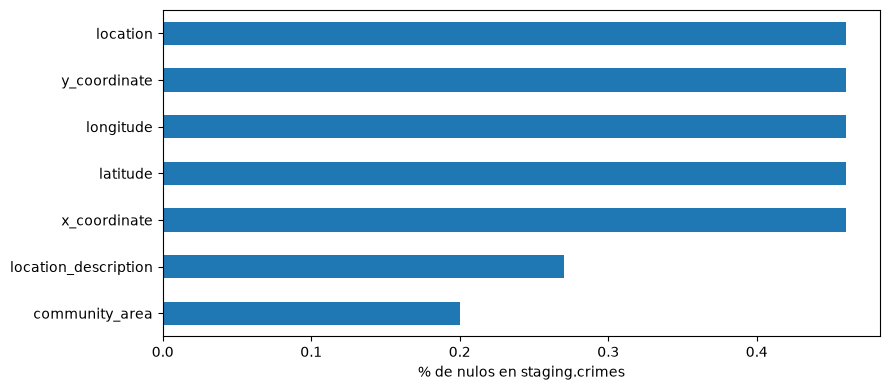

In [16]:
null_pct = (df.isna().mean() * 100).round(2)
null_cols = null_pct[null_pct > 0].sort_values(ascending=False)
display(null_cols.to_frame("pct_null"))
ax = null_cols.sort_values().plot.barh(figsize=(9, 4))
ax.set_xlabel("% de nulos en staging.crimes")
plt.tight_layout()  # los datasets de Chicago suelen tener más nulos en ward/x/y/community_area


## 3 · Distribuciones de negocio (crimen)


,count
primary_type,
THEFT,4191
BATTERY,3712
CRIMINAL DAMAGE,2151
ASSAULT,1973
MOTOR VEHICLE THEFT,1473
OTHER OFFENSE,1257
BURGLARY,1206
DECEPTIVE PRACTICE,894
NARCOTICS,562


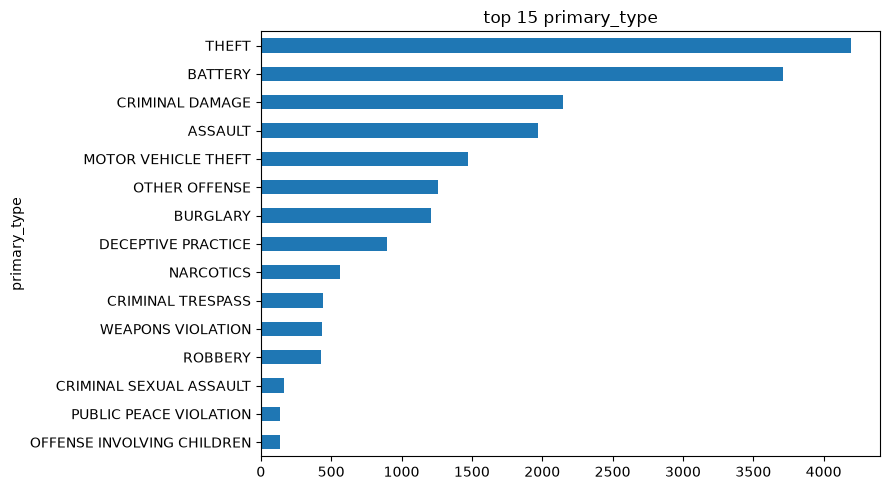

In [21]:
# primary_type: tipo del crimen (el dashboard agrupará por esto)
top_types = df["primary_type"].value_counts().head(15)
display(top_types.to_frame("count"))
top_types.sort_values().plot.barh(figsize=(9, 5), title="top 15 primary_type")
plt.tight_layout()


In [22]:
# arrest / domestic: proporciones de los flags de negocio
display(df[["arrest", "domestic"]].mean().round(4).to_frame("rate"))
df["year"].value_counts().sort_index().to_frame("rows")


,rate
arrest,0.1451
domestic,0.1944


,rows
year,
2026,19642


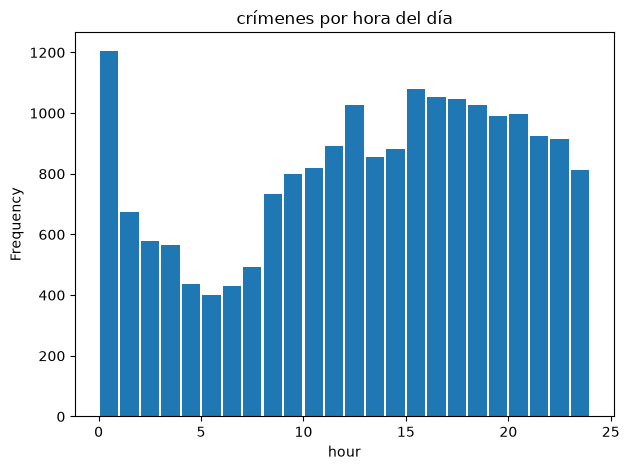

In [23]:
# hora del día: histograma de 24 bins (busca picos nocturnos/vespertinos)
ax = df["date"].dt.hour.plot.hist(bins=24, range=(0, 24), rwidth=0.9,
                                  title="crímenes por hora del día")
ax.set_xlabel("hour"); plt.tight_layout()


,area,area_name,crimes
0,25,Austin,927
1,8,Near North Side,871
2,28,Near West Side,845
3,43,South Shore,695
4,32,Loop,679
5,24,West Town,600
6,71,Auburn Gresham,571
7,69,Greater Grand Crossing,552
8,29,North Lawndale,487
9,23,Humboldt Park,477


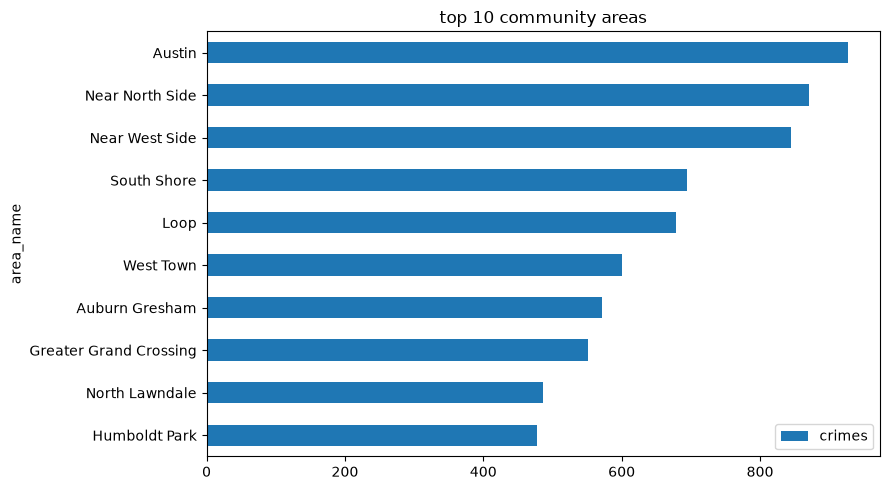

In [24]:
# top 10 community areas CON NOMBRES reales (seed del Paso 3)
TOP_AREAS_SQL = """
SELECT s.community_area           AS area,
       a.community_area_name      AS area_name,
       count(*)                   AS crimes
FROM staging.crimes s
JOIN warehouse.dim_community_area a ON a.community_area = s.community_area
GROUP BY 1, 2
ORDER BY crimes DESC
LIMIT 10
"""
top_areas = df_from_query(conn, TOP_AREAS_SQL)
display(top_areas)
top_areas.sort_values("crimes").plot.barh(
    x="area_name", y="crimes", figsize=(9, 5), title="top 10 community areas")
plt.tight_layout()


## 4 · Impacto del cleaning: raw vs staging


In [25]:
CLEAN_SQL = """
SELECT
  (SELECT count(*) FROM raw.crimes)                                               AS raw_rows,
  (SELECT count(*) FROM staging.crimes)                                           AS staging_rows,
  (SELECT count(*) FROM raw.crimes WHERE latitude = 0 AND longitude = 0)          AS raw_zero_coords,
  (SELECT count(*) FROM raw.crimes WHERE primary_type = '')                       AS raw_empty_types,
  (SELECT count(*) FROM staging.crimes WHERE latitude IS NULL AND longitude IS NULL) AS staging_null_coords,
  (SELECT count(*) FROM staging.crimes WHERE primary_type IS NULL)                AS staging_null_types
"""
df_from_query(conn, CLEAN_SQL).T.rename(columns={0: "conteo"})


,conteo
raw_rows,19642
staging_rows,19642
raw_zero_coords,0
raw_empty_types,0
staging_null_coords,90
staging_null_types,0


## 5 · Métricas de calidad (la MISMA fuente que los data tests)


In [ ]:
# quality.quality_report usa el módulo de ingestion (aplicado en Sprint 2,
# compartido con los tests de integración y el smoke script de carga).
with conn.cursor() as cur:
    report = quality.quality_report(cur)
pd.Series(report, name="valor")


total                                                                   19642
duplicate_ids                                                               0
null_ids                                                                    0
out_of_range_coordinates                                                    0
zero_coordinates                                                            0
invalid_community_area                                                      0
empty_primary_type                                                          0
null_rate                   {'date': 0.0, 'latitude': 0.004582018124427247...
Name: valor, dtype: object

## 6 · Conclusiones del análisis
(completar tras ejecutar y leer los outputs — guía de preguntas)

- Ventana de datos: ¿de qué fechas consta? / filas / ventana real de `date`.
- ¿Qué columnas tienen más nulos y a qué hipótesis de negocio responde?
- ¿Top 5 primary_type plausible? (THEFT/BATTERY/... son los típicos)
- ¿Distribución hora del día: dónde están los picos?
- ¿Micro-check de limpieza: filas (0,0) y cadena vacía → NULL correcto?
- La calidad de staging = suficiente para arrancar feature engineering (Paso 4)?
